# GDBN v1: Learning the Network with the Lasso

A **Gaussian dynamic Bayesian network** with arrows from yesterday to today. For each of the 95 variables:

$$x_i(t) = b_i + \sum_{j=1}^{95} w_{ij}\, x_j(t-1) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma_i^2)$$

- The **lasso** sets most $w_{ij}$ to exactly 0. A nonzero $w_{ij}$ is an **arrow $j$ (yesterday) → $i$ (today)**.
- $\sigma_i$ gives every prediction an **uncertainty range**.
- All arrows go forward in time, so the graph can never loop (a 2-time-slice transition model).

**Steps:**
1. Build pairs and standardize (training statistics only)
2. One lasso per variable; choose λ on validation (2022)
3. Read off the network (weights, edges)
4. Refit the chosen edges without shrinkage, and estimate σ
5. Stability selection: how reliable is each edge?
6. Check the graph (upstream)
7. Check predictions vs baselines (downstream, validation)
8. Save results
9. Final test (2023–2024): **run only once, at the very end**

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.linear_model import lasso_path
from gdbn_utils import (load_data, make_pairs, standardizer, baseline_predictions,
                        evaluate, summarize, dm_report, RESULTS, Z90)

pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

wide, split, info = load_data()
RET, SENT, ATTN, STOCKS, SECTOR = info["RET"], info["SENT"], info["ATTN"], info["STOCKS"], info["SECTOR"]
ticker, kind = info["ticker"], info["kind"]
VARS = list(wide.columns)

## 1. Pairs and standardization

$X$ = all 95 variables on day $t-1$; $Y$ = all 95 variables on day $t$. Both are converted to z-scores using **training means and standard deviations only**, so returns (±0.02) and attention (0–5) are on the same scale for the lasso penalty.

In [2]:
X, Y, labels = make_pairs(wide, split)
tr, va = (labels == "train").values, (labels == "validation").values

mu, sd = standardizer(wide[split == "train"])
Xz, Yz = (X - mu) / sd, (Y - mu) / sd
print(f"train pairs: {tr.sum()}, validation pairs: {va.sum()}, variables: {len(VARS)}")

train pairs: 1762, validation pairs: 251, variables: 95


## 2. One lasso per variable, λ chosen on validation

For each target, fit the whole **lasso path** (many λ values) on training data, then measure the error on 2022 for each λ. Two choices:
- **best λ:** lowest validation error.
- **1-SE λ:** the *largest* λ (sparsest graph) whose validation error is within one standard error of the best. A common rule for a cleaner graph at almost no cost in accuracy.

In [3]:
Xtr, Xva = Xz.values[tr], Xz.values[va]
x_mean = Xtr.mean(axis=0)
Xtr_c, Xva_c = Xtr - x_mean, Xva - x_mean

W = {"best": np.zeros((len(VARS), len(VARS))), "1se": np.zeros((len(VARS), len(VARS)))}
B = {"best": np.zeros(len(VARS)), "1se": np.zeros(len(VARS))}
chosen = []

for i, target in enumerate(VARS):
    y_tr, y_va = Yz[target].values[tr], Yz[target].values[va]
    y_mean = y_tr.mean()
    alphas, coefs, _ = lasso_path(Xtr_c, y_tr - y_mean, n_alphas=60, eps=1e-3)   # coefs: (95, n_alphas)
    val_pred = y_mean + Xva_c @ coefs                                            # (n_val, n_alphas)
    sq_err = (y_va[:, None] - val_pred) ** 2
    mse = sq_err.mean(axis=0)
    k_best = int(np.argmin(mse))
    se_best = sq_err[:, k_best].std(ddof=1) / np.sqrt(len(y_va))
    k_1se = int(np.min(np.where(mse <= mse[k_best] + se_best)[0]))  # alphas are descending -> smallest index = largest alpha
    for name, k in [("best", k_best), ("1se", k_1se)]:
        W[name][i] = coefs[:, k]
        B[name][i] = y_mean - x_mean @ coefs[:, k]
    chosen.append({"target": target, "alpha_best": alphas[k_best], "alpha_1se": alphas[k_1se],
                   "edges_best": int((coefs[:, k_best] != 0).sum()), "edges_1se": int((coefs[:, k_1se] != 0).sum())})

chosen = pd.DataFrame(chosen).set_index("target")
for name in ["best", "1se"]:
    print(f"{name:>4} λ: {int((W[name] != 0).sum()):,} edges out of {len(VARS)**2:,} possible")
chosen.groupby(lambda c: kind(c))[["edges_best", "edges_1se"]].mean().round(1).rename_axis("target type")

best λ: 2,620 edges out of 9,025 possible
 1se λ: 199 edges out of 9,025 possible


,edges_best,edges_1se
target type,,
attn,31.7,2.8
ret,11.2,0.1
sent,42.6,3.7


**Average number of incoming arrows per target, by type.** Expect few arrows into **returns** (hard to predict from yesterday) and more into the **news variables** (news volume and tone persist from day to day). If the 1-SE λ keeps **no** arrows into returns, that is a real finding: no input from yesterday helps predict today's returns reliably enough to survive the stricter rule.

## 3. The network

$W[i, j]$ is the weight of the arrow from variable $j$ (yesterday) to variable $i$ (today), in standardized units. Below: the full 95 × 95 weight matrix (1-SE λ), grouped by type.

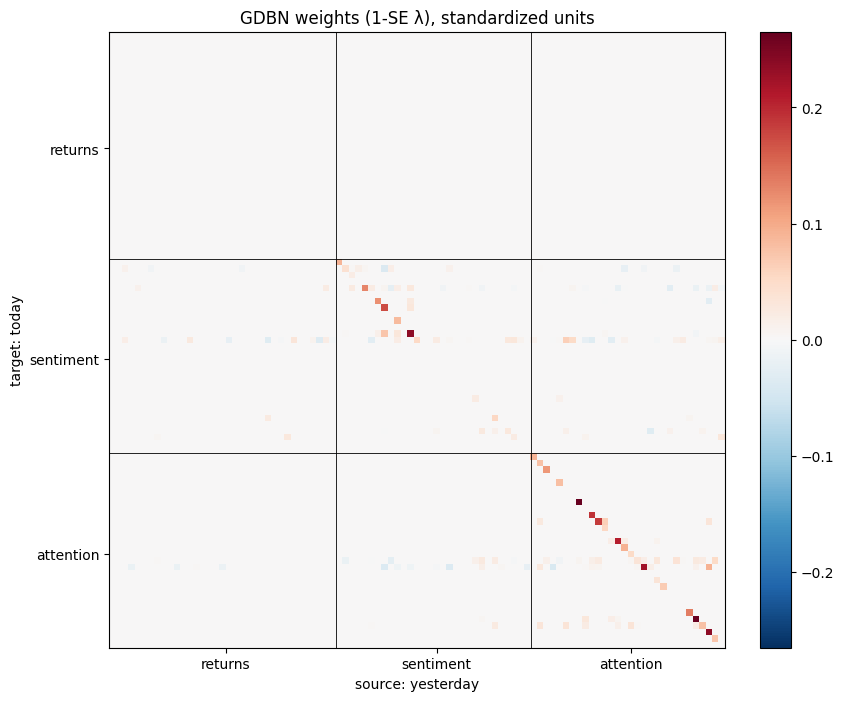

Edges by type (1-SE λ):
self_loop    cross  self-loop
type                         
attn → attn     39         20
attn → sent     43          0
ret → attn       5          0
ret → ret        3          0
ret → sent      19          0
sent → attn     20          0
sent → sent     37         13


In [4]:
def edge_list(Wm):
    i_idx, j_idx = np.nonzero(Wm)
    return pd.DataFrame({"source (t-1)": [VARS[j] for j in j_idx], "target (t)": [VARS[i] for i in i_idx],
                         "weight": Wm[i_idx, j_idx]})

edges = {name: edge_list(W[name]) for name in W}

fig, ax = plt.subplots(figsize=(9, 8))
lim = np.abs(W["1se"]).max() or 1
im = ax.imshow(W["1se"], cmap="RdBu_r", vmin=-lim, vmax=lim)
for b in [len(RET), len(RET) + len(SENT)]:
    ax.axhline(b - 0.5, color="black", lw=0.6); ax.axvline(b - 0.5, color="black", lw=0.6)
ticks = [len(RET) / 2, len(RET) + len(SENT) / 2, len(RET) + len(SENT) + len(ATTN) / 2]
ax.set_xticks(ticks, ["returns", "sentiment", "attention"]); ax.set_yticks(ticks, ["returns", "sentiment", "attention"])
ax.set_xlabel("source: yesterday"); ax.set_ylabel("target: today")
fig.colorbar(im, fraction=0.046); ax.set_title("GDBN weights (1-SE λ), standardized units")
plt.show()

e = edges["1se"].assign(type=lambda d: d["source (t-1)"].map(kind) + " → " + d["target (t)"].map(kind),
                       self_loop=lambda d: d["source (t-1)"] == d["target (t)"])
print("Edges by type (1-SE λ):")
print(e.groupby(["type", "self_loop"]).size().unstack(fill_value=0).rename(columns={False: "cross", True: "self-loop"}).to_string())

In [5]:
# Strongest edges between DIFFERENT variables (1-SE λ)
cross = e[~e["self_loop"]].reindex(e[~e["self_loop"]]["weight"].abs().sort_values(ascending=False).index)
cross.head(20)

,source (t-1),target (t),weight,type,self_loop
177,ABBV_attn,OXY_attn,0.0923,attn → attn,False
52,BAC_sent,C_sent,0.0739,sent → sent,False
82,META_attn,XOM_sent,0.0635,attn → sent,False
123,C_attn,WFC_attn,0.0624,attn → attn,False
154,CAT_attn,EOG_attn,0.0510,attn → attn,False
83,JPM_attn,XOM_sent,0.0501,attn → sent,False
169,GOOGL_attn,OXY_attn,-0.0406,attn → attn,False
11,BAC_sent,MSFT_sent,-0.0386,sent → sent,False
159,BAC_sent,OXY_attn,-0.0365,sent → attn,False
163,OXY_sent,OXY_attn,-0.0362,sent → attn,False


## 4. Refit without shrinkage, and estimate σ

The lasso shrinks the weights it keeps toward 0. Use it only to **choose** the edges, then refit ordinary regression on just those edges (a "relaxed lasso"). The training residuals give each variable's noise level $\sigma_i$, which makes this a **Gaussian** DBN:

$$x_i(t) \sim \mathcal{N}\!\left(b_i + \textstyle\sum_j w_{ij} x_j(t-1),\ \sigma_i^2\right)$$

In [6]:
def relaxed_refit(Wm):
    W_r, B_r, S_r = np.zeros_like(Wm), np.zeros(len(VARS)), np.zeros(len(VARS))
    for i, target in enumerate(VARS):
        cols = np.nonzero(Wm[i])[0]
        y = Yz[target].values[tr]
        A = np.column_stack([np.ones(tr.sum()), Xtr[:, cols]])
        coef, *_ = np.linalg.lstsq(A, y, rcond=None)
        B_r[i], W_r[i, cols] = coef[0], coef[1:]
        resid = y - A @ coef
        S_r[i] = resid.std(ddof=A.shape[1])
    return W_r, B_r, S_r

models = {}
for name in ["best", "1se"]:
    models[f"lasso_{name}"] = (W[name], B[name], None)
    models[f"refit_{name}"] = relaxed_refit(W[name])

def predict(model, Xz_rows):
    Wm, Bm, _ = model
    return pd.DataFrame(Xz_rows.values @ Wm.T + Bm, index=Xz_rows.index, columns=VARS)

print("σ (standardized units) for a few targets, refit_1se:")
print(pd.Series(models["refit_1se"][2], index=VARS)[[RET[0], SENT[0], ATTN[0]]].round(3).to_string())

σ (standardized units) for a few targets, refit_1se:
AAPL_ret     1.000
AAPL_sent    0.970
AAPL_attn    0.903


## 5. Stability selection: how reliable is each edge?

Refit the lasso many times on **random halves of the training period** (in 1-month blocks, to respect time). Record how often each edge is chosen, at **both** λ settings:
- **≥ 70%:** a stable edge (shows up no matter which years you train on).
- **low:** probably noise.

These frequencies are **edge probabilities**, which can later be passed to the TBGNN as edge confidence. Note: at a very small λ almost every input is kept, so nearly everything looks "stable"; the 1-SE λ gives the more meaningful stability numbers. (Takes under a minute.)

In [7]:
from sklearn.linear_model import Lasso

N_RESAMPLES, BLOCK = 50, 21
n_tr = tr.sum()
blocks = np.array_split(np.arange(n_tr), int(np.ceil(n_tr / BLOCK)))
samples = [np.concatenate([blocks[b] for b in rng.choice(len(blocks), size=len(blocks) // 2, replace=False)])
           for _ in range(N_RESAMPLES)]

def stability(alpha_col):
    freq = np.zeros((len(VARS), len(VARS)))
    for rows in samples:
        Xs = Xtr[rows]
        for i, target in enumerate(VARS):
            fit = Lasso(alpha=chosen.loc[target, alpha_col], max_iter=5000).fit(Xs, Yz[target].values[tr][rows])
            freq[i] += fit.coef_ != 0
    return freq / N_RESAMPLES

freq = {"best": stability("alpha_best"), "1se": stability("alpha_1se")}

rows = []
for name in ["best", "1se"]:
    sel = W[name] != 0
    for t_kind in ["ret", "sent", "attn"]:
        r = np.array([kind(v) == t_kind for v in VARS])
        n_sel = int(sel[r].sum())
        n_stable = int((sel[r] & (freq[name][r] >= 0.7)).sum())
        rows.append({"λ": name, "target type": t_kind, "edges in full fit": n_sel,
                     "of which stable (≥70%)": n_stable, "share stable": n_stable / n_sel if n_sel else np.nan})
print(pd.DataFrame(rows).to_string(index=False))

stab = {name: edge_list(np.where(freq[name] > 0, freq[name], 0)).rename(columns={"weight": "frequency"})
              .sort_values("frequency", ascending=False) for name in freq}
stable = stab["1se"][(stab["1se"]["frequency"] >= 0.7) & (stab["1se"]["source (t-1)"] != stab["1se"]["target (t)"])]
print(f"\nMost stable edges between different variables (1-SE λ):")
stable.head(20)

   λ target type  edges in full fit  of which stable (≥70%)  share stable
best         ret                392                     234        0.5969
best        sent               1277                     983        0.7698
best        attn                951                     654        0.6877
 1se         ret                  3                       0        0.0000
 1se        sent                112                      58        0.5179
 1se        attn                 84                      52        0.6190

Most stable edges between different variables (1-SE λ):


,source (t-1),target (t),frequency
802,BAC_sent,C_sent,1.00
1241,PG_attn,MRK_sent,0.98
1587,CAT_attn,EOG_attn,0.98
1677,ABBV_attn,OXY_attn,0.96
1627,BAC_sent,OXY_attn,0.94
1827,UNH_sent,MRK_attn,0.94
912,META_attn,XOM_sent,0.94
913,JPM_attn,XOM_sent,0.94
1402,C_attn,WFC_attn,0.94
588,BAC_sent,MSFT_sent,0.90


## 6. Check the graph (upstream)

Does the learned structure make economic sense? (Compare with the Niu et al. idea: interpret the graph before trusting its predictions.)

In [8]:
energy = [t for t in STOCKS if SECTOR[t] == "Energy"]
pairs = [(a, b) for a in STOCKS for b in STOCKS if a != b]
chance = np.mean([SECTOR[a] == SECTOR[b] for a, b in pairs])

def tag(edges_df):
    G = edges_df.copy()
    G["src_tk"], G["dst_tk"] = G["source (t-1)"].map(ticker), G["target (t)"].map(ticker)
    G["src_kind"], G["dst_kind"] = G["source (t-1)"].map(kind), G["target (t)"].map(kind)
    return G

def upstream(G, name):
    print(f"===== {name} λ graph: {len(G)} edges =====")
    rr = G[(G["src_kind"] == "ret") & (G["dst_kind"] == "ret") & (G["src_tk"] != G["dst_tk"])
           & G["src_tk"].isin(STOCKS) & G["dst_tk"].isin(STOCKS)]
    same = (rr["src_tk"].map(SECTOR) == rr["dst_tk"].map(SECTOR)).mean() if len(rr) else float("nan")
    print(f"(a) stock→stock return edges: {len(rr)}" + (f"; same-sector share {same:.0%} (chance: {chance:.0%})" if len(rr) else ""))
    oil = G[G["src_tk"] == "USO"]
    print(f"(b) edges out of oil (USO): {len(oil)}; to energy-stock variables: {oil['dst_tk'].isin(energy).sum()}")
    own = G[G["src_kind"].isin(["sent", "attn"]) & (G["dst_kind"] == "ret") & (G["src_tk"] == G["dst_tk"])]
    print(f"(c) own news → own next-day return: {len(own)} edges")
    print(f"(d) return → next-day attention: {len(G[(G['src_kind'] == 'ret') & (G['dst_kind'] == 'attn')])} edges")
    sl = G[G["source (t-1)"] == G["target (t)"]]
    print(f"(e) self-loops by type: {sl['dst_kind'].value_counts().to_dict()}\n")
    return rr

graphs = {name: tag(edges[name]) for name in edges}
rr_best = upstream(graphs["best"], "best")
_ = upstream(graphs["1se"], "1-SE")

===== best λ graph: 2620 edges =====
(a) stock→stock return edges: 135; same-sector share 15% (chance: 15%)
(b) edges out of oil (USO): 25; to energy-stock variables: 11
(c) own news → own next-day return: 8 edges
(d) return → next-day attention: 233 edges
(e) self-loops by type: {'sent': 30, 'attn': 30, 'ret': 6}

===== 1-SE λ graph: 199 edges =====
(a) stock→stock return edges: 3; same-sector share 0% (chance: 15%)
(b) edges out of oil (USO): 1; to energy-stock variables: 1
(c) own news → own next-day return: 0 edges
(d) return → next-day attention: 5 edges
(e) self-loops by type: {'attn': 20, 'sent': 13}



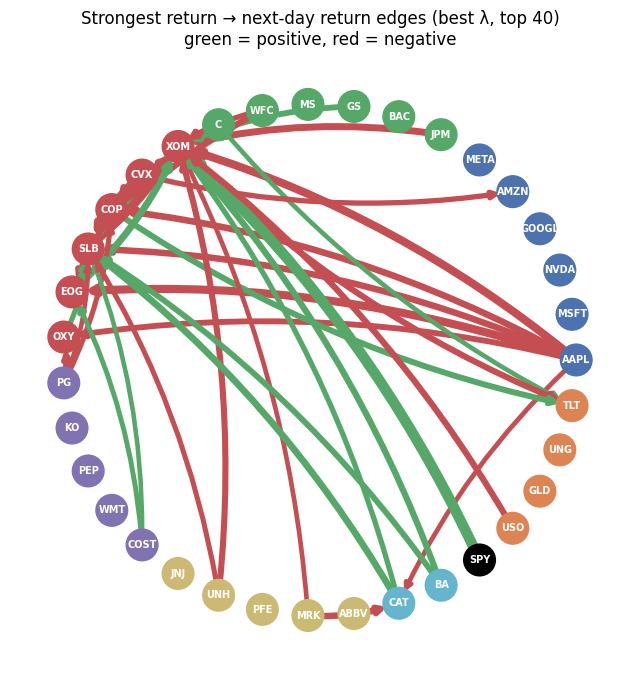

In [9]:
# Draw the return-only part of the network (35 nodes), colored by sector
colors = {"Tech": "#4c72b0", "Banks": "#55a868", "Energy": "#c44e52", "Staples": "#8172b2",
          "Healthcare": "#ccb974", "Industrials": "#64b5cd", "Market": "black", "Commodities/Rates": "#dd8452"}
G = graphs["best"]  # the 1-SE graph usually has no return -> return edges, so draw the best-λ graph
sub = G[(G["src_kind"] == "ret") & (G["dst_kind"] == "ret") & (G["src_tk"] != G["dst_tk"])]
sub = sub.reindex(sub["weight"].abs().sort_values(ascending=False).index).head(40)  # strongest 40, to stay readable
net = nx.DiGraph()
net.add_nodes_from(ticker(c) for c in RET)
for _, r in sub.iterrows():
    net.add_edge(r["src_tk"], r["dst_tk"], weight=r["weight"])
pos = nx.circular_layout(net)
plt.figure(figsize=(8, 8))
nx.draw_networkx_nodes(net, pos, node_color=[colors[SECTOR[n]] for n in net.nodes], node_size=520)
nx.draw_networkx_labels(net, pos, font_size=7, font_color="white", font_weight="bold")
nx.draw_networkx_edges(net, pos, edge_color=["#c44e52" if net[u][v]["weight"] < 0 else "#55a868" for u, v in net.edges],
                       width=[1 + 40 * abs(net[u][v]["weight"]) for u, v in net.edges], arrowsize=10,
                       connectionstyle="arc3,rad=0.1")
plt.title(f"Strongest return → next-day return edges (best λ, top {net.number_of_edges()})\ngreen = positive, red = negative")
plt.axis("off"); plt.show()

## 7. Check predictions vs baselines (downstream, validation 2022)

Predictions are converted back to return units. Uncertainty ranges use each model's $\sigma$ (± 1.645 σ for a 90% range).

In [10]:
val = labels == "validation"
y_val = Y.loc[val, RET]
base_preds, base_sig = baseline_predictions(X, Y, labels, RET)
bench_mse = ((y_val - base_preds["hist_mean"].loc[val]) ** 2).mean()

results, errors = {}, {}
for name, p in base_preds.items():
    results[name] = summarize(evaluate(y_val, p.loc[val], base_sig[name], bench_mse))
    errors[name] = y_val - p.loc[val]

for name, model in models.items():
    pz = predict(model, Xz.loc[val])
    p = pz[RET] * sd[RET] + mu[RET]                       # back to return units
    sig = None if model[2] is None else pd.Series(model[2], index=VARS)[RET] * sd[RET]
    results[name] = summarize(evaluate(y_val, p, sig, bench_mse))
    errors[name] = y_val - p

table = pd.DataFrame(results).T
table["mse"] *= 1e4
table.rename(columns={"mse": "mse (%^2)"})

,coverage90,direction,mse (%^2),r2_os
zero,0.8536,0.5060,5.6832,1.8253e-03
hist_mean,0.8521,0.4986,5.6986,0.0000e+00
ar1,0.8478,0.4953,5.7517,-1.3134e-02
lasso_best,NaN,0.5034,5.6691,4.5707e-03
refit_best,0.8474,0.5053,5.7198,-5.5895e-03
lasso_1se,NaN,0.4986,5.6986,0.0000e+00
refit_1se,0.8521,0.5001,5.6971,9.9468e-05


In [11]:
print("Diebold–Mariano tests vs the historical mean:")
for name in ["lasso_best", "refit_best", "lasso_1se", "refit_1se", "ar1"]:
    print(" ", dm_report(name, "hist_mean", errors[name], errors["hist_mean"]))

Diebold–Mariano tests vs the historical mean:
   lasso_best vs hist_mean: mean loss diff = -2.96e-06, t = -1.00, p = 0.318 -> difference not significant
   refit_best vs hist_mean: mean loss diff = +2.11e-06, t = +0.43, p = 0.669 -> difference not significant
    lasso_1se vs hist_mean: identical forecasts (no difference to test)
    refit_1se vs hist_mean: mean loss diff = -1.54e-07, t = -0.23, p = 0.819 -> difference not significant
          ar1 vs hist_mean: mean loss diff = +5.30e-06, t = +2.62, p = 0.009 -> hist_mean is better, significant (p < 0.05)


**How to read this (honestly):**
- If the GDBN's **r2_os** is near 0 and the Diebold–Mariano test is **not significant**, the network does not predict next-day returns better than the historical mean in 2022. That is a common, legitimate finding: the edges can still be real (Step 6) even if they are too weak to trade on.
- **coverage90** shows whether the uncertainty ranges are honest. Below 90% in 2022 is expected (more volatile than training); this motivates the **rolling-window** GDBN, which re-estimates σ as markets change.

### A note on same-day structure (for GDBN v2)

This version only has arrows from **yesterday to today**. Daily returns are hard to predict from yesterday, so few (or no) arrows may point into returns. But stocks are strongly related **on the same day** (the sector correlations in the sanity check). A full dynamic Bayesian network can also have arrows **within** a day (like the Chapter 3 network, applied to each day). A natural v2: keep these lagged arrows, then learn same-day structure among the leftover errors (e.g., a Gaussian Bayesian network or a sparse precision matrix on the residuals). That is where sector links should appear.

## 8. Save results

In [12]:
RESULTS.mkdir(parents=True, exist_ok=True)
for name in ["best", "1se"]:
    pd.DataFrame(W[name], index=VARS, columns=VARS).to_csv(RESULTS / f"gdbn_W_{name}.csv")       # rows = target (t), cols = source (t-1)
    edges[name].to_csv(RESULTS / f"gdbn_edges_{name}.csv", index=False)
for name in stab:
    stab[name].to_csv(RESULTS / f"gdbn_edge_stability_{name}.csv", index=False)
pd.Series(models["refit_1se"][2], index=VARS, name="sigma_z").to_csv(RESULTS / "gdbn_sigma_refit_1se.csv")
chosen.to_csv(RESULTS / "gdbn_chosen_alpha.csv")
table.to_csv(RESULTS / "gdbn_validation_results.csv")
print("Saved to", RESULTS)

Saved to /Users/max_lovinger/Documents/Thesis/CoreFragment/data/results
